In [51]:
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph,START,END
from typing import TypedDict
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver

In [52]:
import os

In [53]:
apikey = os.getenv("GROQ_API_KEY")

In [54]:
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
    api_key=apikey
)

In [55]:
#joke=> topic, 
#joke => explaination

In [56]:
class Jokestate(TypedDict):
    topic : str
    joke : str
    explaination : str

In [57]:
def generate_joke(state:Jokestate):
    prompt = f"Generate a joke on the given topic : {state['topic']}"
    response = llm.invoke(prompt).content

    return {"joke":response}

In [58]:
def generate_exp(state:Jokestate):
    prompt = f"Write an explaination for the joke - {state['joke']}"
    response = llm.invoke(prompt).content
    return {"explaination":response}

In [59]:
graph = StateGraph(Jokestate)
graph.add_node("generate_joke",generate_joke)
graph.add_node("generate_exp",generate_exp)

graph.add_edge(START,"generate_joke")
graph.add_edge("generate_joke","generate_exp")
graph.add_edge("generate_exp",END)

checkpointer = InMemorySaver()
workflow = graph.compile(checkpointer=checkpointer)

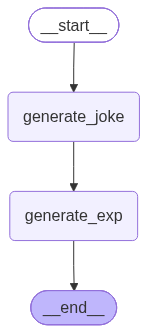

In [60]:
workflow

In [61]:
config = {"configurable":{"thread_id":"1"}}
workflow.invoke({"topic":"burger"},config=config)

{'topic': 'burger',
 'joke': 'Why did the burger go to therapy?\n\nBecause it had too many layers of *lettuce* and *feeling* *un-**buns**ed*!',
 'explaination': ''}

In [62]:
#get_state
workflow.get_state(config)

StateSnapshot(values={'topic': 'burger', 'joke': 'Why did the burger go to therapy?\n\nBecause it had too many layers of *lettuce* and *feeling* *un-**buns**ed*!', 'explaination': ''}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dcfd3-2dcd-620f-8002-5301bf3feb6e'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-11-10T11:52:26.336395+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dcfd3-14a8-6792-8001-9b1738c5cffe'}}, tasks=(), interrupts=())

In [63]:
for state in workflow.get_state_history(config):
    print(state)

StateSnapshot(values={'topic': 'burger', 'joke': 'Why did the burger go to therapy?\n\nBecause it had too many layers of *lettuce* and *feeling* *un-**buns**ed*!', 'explaination': ''}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dcfd3-2dcd-620f-8002-5301bf3feb6e'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-11-10T11:52:26.336395+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dcfd3-14a8-6792-8001-9b1738c5cffe'}}, tasks=(), interrupts=())
StateSnapshot(values={'topic': 'burger', 'joke': 'Why did the burger go to therapy?\n\nBecause it had too many layers of *lettuce* and *feeling* *un-**buns**ed*!'}, next=('generate_exp',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dcfd3-14a8-6792-8001-9b1738c5cffe'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-11-10T11:52:23.700031+00:00', parent_confi

In [65]:
config2 = {"configurable":{"thread_id":"2"}}

workflow.invoke({"topic":"pizza"},config=config2)

{'topic': 'pizza',
 'joke': 'Why did the pizza apply for a job?\n\nBecause it wanted to get a *crust* of a living! 🍕😄',
 'explaination': '**Why the joke works – a quick “crust‑of‑a‑living” breakdown**\n\n| Element | What it is | How it plays on words |\n|---------|------------|-----------------------|\n| **Pizza** | A food that literally has a *crust* | The joke gives the pizza a human goal (applying for a job) so we can talk about “money” in a pizza‑centric way. |\n| **“Crust”** | The outer edge of a pizza | It sounds like the word *cost* (the amount of money you need). The joke swaps the two words to make a pun. |\n| **“Living”** | A way of saying “livelihood” or “income” | In the phrase “cost of living,” *living* refers to the expenses needed to survive. |\n| **The punchline** | “Because it wanted to get a *crust* of a living!” | The pizza wants to earn a *crust* (money) to cover its *living* (expenses). The phrase is a playful twist on the common expression “cost of living.” |\n\n#

In [66]:
list(workflow.get_state_history(config))

[StateSnapshot(values={'topic': 'burger', 'joke': 'Why did the burger go to therapy?\n\nBecause it had too many layers of *lettuce* and *feeling* *un-**buns**ed*!', 'explaination': ''}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dcfd3-2dcd-620f-8002-5301bf3feb6e'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-11-10T11:52:26.336395+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dcfd3-14a8-6792-8001-9b1738c5cffe'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'topic': 'burger', 'joke': 'Why did the burger go to therapy?\n\nBecause it had too many layers of *lettuce* and *feeling* *un-**buns**ed*!'}, next=('generate_exp',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dcfd3-14a8-6792-8001-9b1738c5cffe'}}, metadata={'source': 'loop', 'step': 1, 'parents': {}}, created_at='2026-11-10T11:52:23.700031+00:00', parent_co

In [68]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza apply for a job?\n\nBecause it wanted to get a *crust* of a living! 🍕😄', 'explaination': '**Why the joke works – a quick “crust‑of‑a‑living” breakdown**\n\n| Element | What it is | How it plays on words |\n|---------|------------|-----------------------|\n| **Pizza** | A food that literally has a *crust* | The joke gives the pizza a human goal (applying for a job) so we can talk about “money” in a pizza‑centric way. |\n| **“Crust”** | The outer edge of a pizza | It sounds like the word *cost* (the amount of money you need). The joke swaps the two words to make a pun. |\n| **“Living”** | A way of saying “livelihood” or “income” | In the phrase “cost of living,” *living* refers to the expenses needed to survive. |\n| **The punchline** | “Because it wanted to get a *crust* of a living!” | The pizza wants to earn a *crust* (money) to cover its *living* (expenses). The phrase is a playful twist on the common expression “cos